Member: Seunghyun Park, Hyunwoo sun

Data URL: https://archive.ics.uci.edu/datasets?search=Seeds

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Use raw string r'\s+' to prevent syntax warnings and read data on whitespace.
df = pd.read_csv('seeds_dataset.txt', sep=r'\s+', names=['area', 'perimeter', 'compactness', 'kernel_length',
           'kernel_width', 'asymmetry', 'groove_length', 'target'], na_values='?')

df = df.dropna()

In [3]:
df.head()

,area,perimeter,compactness,kernel_length,kernel_width,asymmetry,groove_length,target
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [4]:
from sklearn.preprocessing import StandardScaler

features=['area', 'perimeter', 'compactness', 'kernel_length',
          'kernel_width', 'asymmetry', 'groove_length']

#separating out the features
x=df.loc[:,features].values

#separating out the target
y=df.loc[:,['target']].values

#Standardizing the features
x=StandardScaler().fit_transform(x)

In [5]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
principalComponents=pca.fit_transform(x)
principalDf=pd.DataFrame(data=principalComponents, columns=['principal comp 1', 'principal comp 2'])

In [6]:
principalDf.head()

,principal comp 1,principal comp 2
0,0.317047,-0.783669
1,-0.003386,-1.913214
2,-0.459443,-1.907225
3,-0.591936,-1.931069
4,1.102910,-2.068090


In [7]:
finalDf=pd.concat([principalDf, df[['target']]], axis=1)
finalDf.head()

,principal comp 1,principal comp 2,target
0,0.317047,-0.783669,1
1,-0.003386,-1.913214,1
2,-0.459443,-1.907225,1
3,-0.591936,-1.931069,1
4,1.102910,-2.068090,1


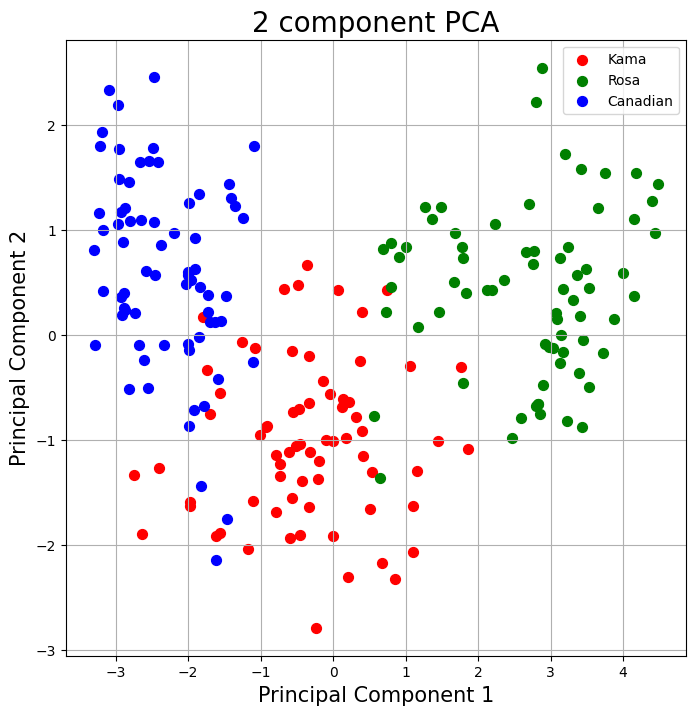

In [8]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1)
ax.set_xlabel('Principal Component 1', fontsize = 15)
ax.set_ylabel('Principal Component 2', fontsize = 15)
ax.set_title('2 component PCA', fontsize = 20)

targets = [1, 2, 3]
colors = ['r', 'g', 'b']
for target, color in zip(targets,colors):
    indicesToKeep = finalDf['target'] == target
    ax.scatter(finalDf.loc[indicesToKeep, 'principal comp 1']
               , finalDf.loc[indicesToKeep, 'principal comp 2']
               , c = color
               , s = 50)
ax.legend(['Kama', 'Rosa', 'Canadian'])
ax.grid()

In [9]:
pca.explained_variance_ratio_

array([0.71874303, 0.17108184])

From the above result, the seven dimensions were reduced to two dimensions using PCA. The first principal component explains 72% of the total variance, and the second principal component explains 17%. Together, they explain 89% of the total variance. This means that the two principal components preserve most of the variance in the original dataset.